<a href="https://colab.research.google.com/github/MrNamu22/Caustic-Ray-Tracing-Simulation/blob/main/Caustic_Curve_Ray_Tracing_Simulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

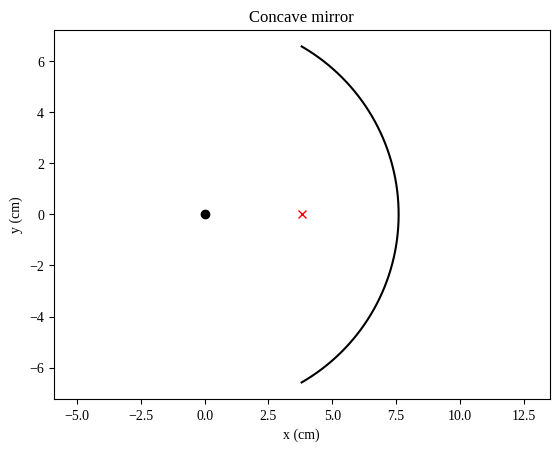

In [35]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Liberation Serif", "DejaVu Serif"]

R = 7.6

theta = np.linspace(-np.radians(60), np.radians(60), 200)
mirror_x = R * np.cos(theta)
mirror_y = R * np.sin(theta)

plt.plot(mirror_x, mirror_y, "k")
plt.plot(0, 0, "ko")
plt.plot(R / 2, 0, "rx")
plt.axis("equal")
plt.title("Concave mirror")
plt.xlabel("x (cm)")
plt.ylabel("y (cm)")
plt.show()

In [36]:
h = 2.0

d = np.array([1.0, 0.0])
S = np.array([-2.0, h])
P = np.array([np.sqrt(R**2 - h**2), h])

print("Direction d:", d)
print("Start S:", S)
print("Hit point P:", P)
print("Distance of P from centre:", np.linalg.norm(P))

Direction d: [1. 0.]
Start S: [-2.  2.]
Hit point P: [7.33212111 2.        ]
Distance of P from centre: 7.6


In [37]:
n = -P / np.linalg.norm(P)
r = d - 2 * np.dot(d, n) * n

print("Normal n:", n)
print("Reflected direction r:", r)
print("Length of r:", np.linalg.norm(r))

angle_in = np.degrees(np.arccos(np.dot(-d, n)))
angle_out = np.degrees(np.arccos(np.dot(r, n)))
print("Angle of incidence:", angle_in)
print("Angle of reflection:", angle_out)

Normal n: [-0.96475278 -0.26315789]
Reflected direction r: [-0.86149584 -0.50776462]
Length of r: 1.0
Angle of incidence: 15.257523290456374
Angle of reflection: 15.257523290456396


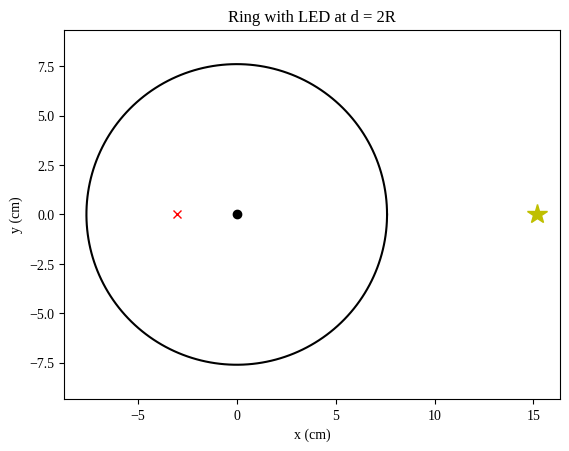

Predicted cusp distance x: 3.04


In [38]:
d = 15.2

angle = np.linspace(0, 2 * np.pi, 400)
ring_x = R * np.cos(angle)
ring_y = R * np.sin(angle)

source = np.array([d, 0.0])
x_pred = R * d / (2 * d + R)

plt.plot(ring_x, ring_y, "k")
plt.plot(0, 0, "ko")
plt.plot(source[0], source[1], "y*", markersize=15)
plt.plot(-x_pred, 0, "rx")
plt.axis("equal")
plt.title("Ring with LED at d = 2R")
plt.xlabel("x (cm)")
plt.ylabel("y (cm)")
plt.show()

print("Predicted cusp distance x:", x_pred)

In [39]:
alpha = np.radians(5)
v = np.array([-np.cos(alpha), np.sin(alpha)])

b = np.dot(source, v)
c = np.dot(source, source) - R**2
t_near = -b - np.sqrt(b**2 - c)
t_far = -b + np.sqrt(b**2 - c)

Q = source + t_far * v

print("Direction v:", v)
print("t at near rim:", t_near)
print("t at far wall:", t_far)
print("Hit point Q:", Q)
print("Distance of Q from centre:", np.linalg.norm(Q))

Direction v: [-0.9961947   0.08715574]
t at near rim: 7.6585111277058076
t at far wall: 22.625807694283257
Hit point Q: [-7.33970967  1.97196907]
Distance of Q from centre: 7.6000000000000005


Reflected direction r: [ 0.90573763 -0.42383882]
Ray crosses axis at x = -3.1256393379026886
Distance from centre: 3.1256393379026886
Mirror equation predicts: 3.04


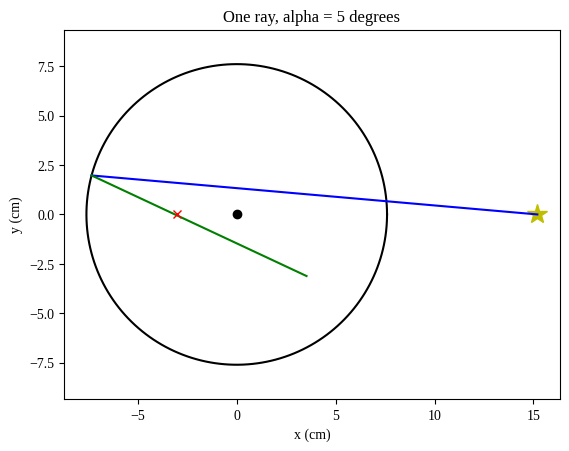

In [40]:
n = Q / R
r = v - 2 * np.dot(v, n) * n

s = -Q[1] / r[1]
x_cross = Q[0] + s * r[0]

print("Reflected direction r:", r)
print("Ray crosses axis at x =", x_cross)
print("Distance from centre:", -x_cross)
print("Mirror equation predicts:", x_pred)

end = Q + 12 * r

plt.plot(ring_x, ring_y, "k")
plt.plot(0, 0, "ko")
plt.plot(source[0], source[1], "y*", markersize=15)
plt.plot([source[0], Q[0]], [source[1], Q[1]], "b")
plt.plot([Q[0], end[0]], [Q[1], end[1]], "g")
plt.plot(-x_pred, 0, "rx")
plt.axis("equal")
plt.title("One ray, alpha = 5 degrees")
plt.xlabel("x (cm)")
plt.ylabel("y (cm)")
plt.show()

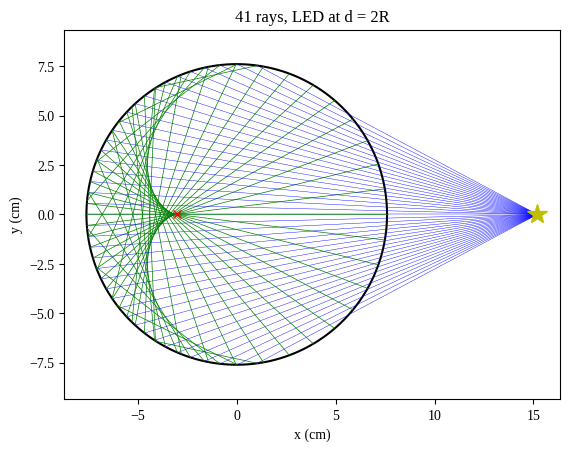

In [41]:
def trace_ray(d, alpha):
    source = np.array([d, 0.0])
    v = np.array([-np.cos(alpha), np.sin(alpha)])
    b = np.dot(source, v)
    c = np.dot(source, source) - R**2
    t_far = -b + np.sqrt(b**2 - c)
    Q = source + t_far * v
    n = Q / R
    r = v - 2 * np.dot(v, n) * n
    return source, Q, r

alphas = np.radians(np.linspace(-28, 28, 41))

plt.plot(ring_x, ring_y, "k")
for alpha in alphas:
    source, Q, r = trace_ray(d, alpha)
    end = Q + (-2 * np.dot(Q, r)) * r
    plt.plot([source[0], Q[0]], [source[1], Q[1]], "b", linewidth=0.3)
    plt.plot([Q[0], end[0]], [Q[1], end[1]], "g", linewidth=0.5)
plt.plot(source[0], source[1], "y*", markersize=15)
plt.plot(-x_pred, 0, "rx")
plt.axis("equal")
plt.title("41 rays, LED at d = 2R")
plt.xlabel("x (cm)")
plt.ylabel("y (cm)")
plt.show()

alpha = 0.01 deg: 3.0400003333733387
alpha = 5 deg:    3.1256393379026886
Mirror equation:  3.04


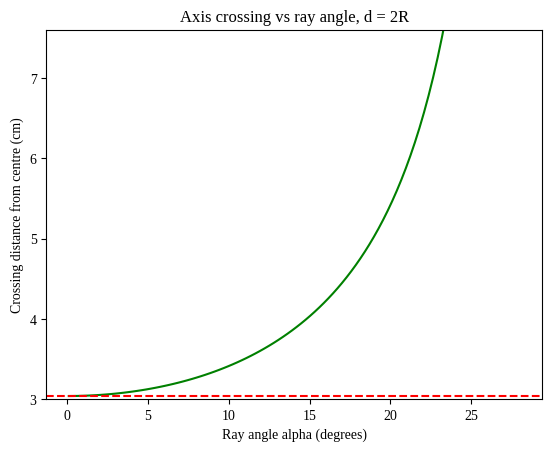

In [42]:
def axis_crossing(d, alpha):
    source, Q, r = trace_ray(d, alpha)
    s = -Q[1] / r[1]
    return -(Q[0] + s * r[0])

print("alpha = 0.01 deg:", axis_crossing(d, np.radians(0.01)))
print("alpha = 5 deg:   ", axis_crossing(d, np.radians(5)))
print("Mirror equation: ", x_pred)

alphas_deg = np.linspace(0.1, 28, 100)
crossings = []
for a in alphas_deg:
    crossings.append(axis_crossing(d, np.radians(a)))

plt.plot(alphas_deg, crossings, "g")
plt.axhline(x_pred, color="r", linestyle="--")
plt.title("Axis crossing vs ray angle, d = 2R")
plt.xlabel("Ray angle alpha (degrees)")
plt.ylabel("Crossing distance from centre (cm)")
plt.ylim(3, 7.6)
plt.show()

Simulated cusp positions: [2.533 2.714 2.85  2.956 3.04  3.167 3.257 3.325 3.378]
Differences (measured - simulated): [-0.053  0.006 -0.01   0.024 -0.     0.013 -0.017 -0.005  0.042]
RMSE (cm): 0.025503644121049555


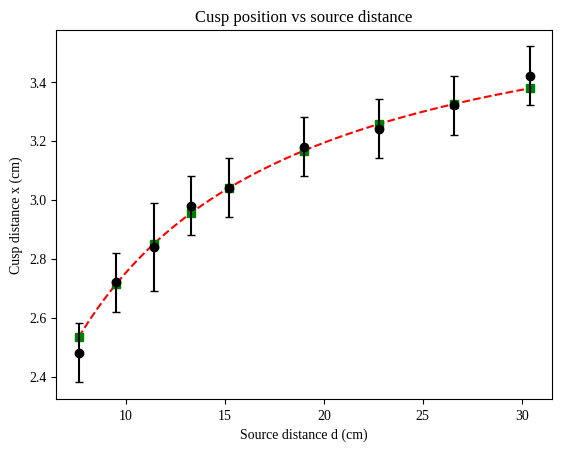

In [43]:
d_values = R * np.array([1, 1.25, 1.5, 1.75, 2, 2.5, 3, 3.5, 4])
x_measured = np.array([2.48, 2.72, 2.84, 2.98, 3.04, 3.18, 3.24, 3.32, 3.42])
x_error = np.array([0.10, 0.10, 0.15, 0.10, 0.10, 0.10, 0.10, 0.10, 0.10])

x_sim = []
for dd in d_values:
    x_sim.append(axis_crossing(dd, np.radians(0.01)))
x_sim = np.array(x_sim)

rmse = np.sqrt(np.mean((x_measured - x_sim) ** 2))
print("Simulated cusp positions:", np.round(x_sim, 3))
print("Differences (measured - simulated):", np.round(x_measured - x_sim, 3))
print("RMSE (cm):", rmse)

d_smooth = np.linspace(7.6, 30.4, 100)
plt.plot(d_smooth, R * d_smooth / (2 * d_smooth + R), "r--")
plt.plot(d_values, x_sim, "gs")
plt.errorbar(d_values, x_measured, yerr=x_error, fmt="ko", capsize=3)
plt.title("Cusp position vs source distance")
plt.xlabel("Source distance d (cm)")
plt.ylabel("Cusp distance x (cm)")
plt.show()

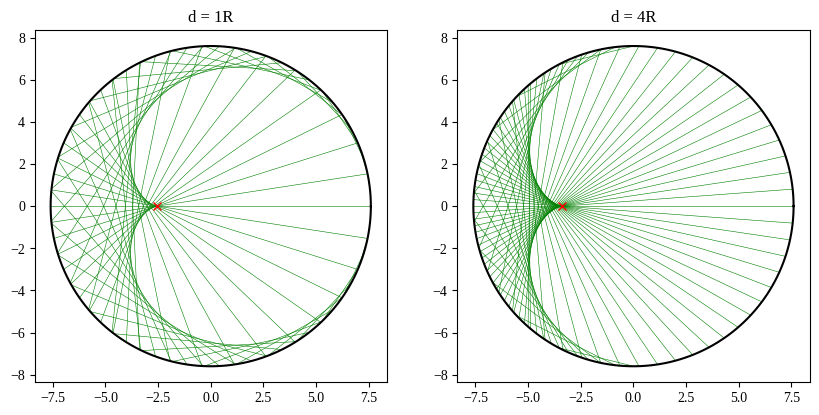

In [44]:
def draw_caustic(ax, dd, title):
    alpha_max = np.arcsin(R / dd) * 0.97
    for alpha in np.linspace(-alpha_max, alpha_max, 61):
        source, Q, r = trace_ray(dd, alpha)
        end = Q + (-2 * np.dot(Q, r)) * r
        ax.plot([Q[0], end[0]], [Q[1], end[1]], "g", linewidth=0.4)
    ax.plot(ring_x, ring_y, "k")
    ax.plot(-R * dd / (2 * dd + R), 0, "rx")
    ax.set_aspect("equal")
    ax.set_title(title)

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 5))
draw_caustic(left, 1 * R, "d = 1R")
draw_caustic(right, 4 * R, "d = 4R")
plt.savefig("caustics_1R_4R.png", dpi=150, bbox_inches="tight")
plt.show()

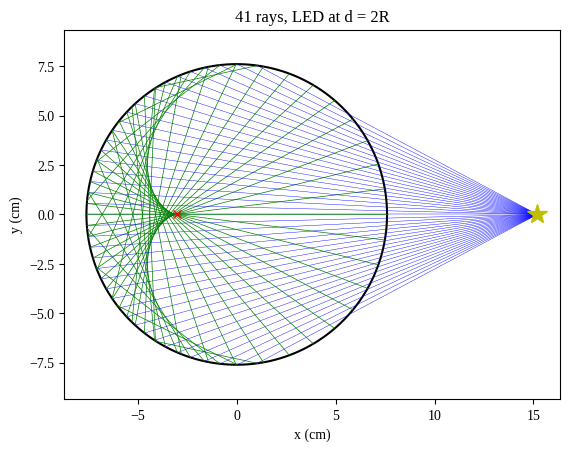

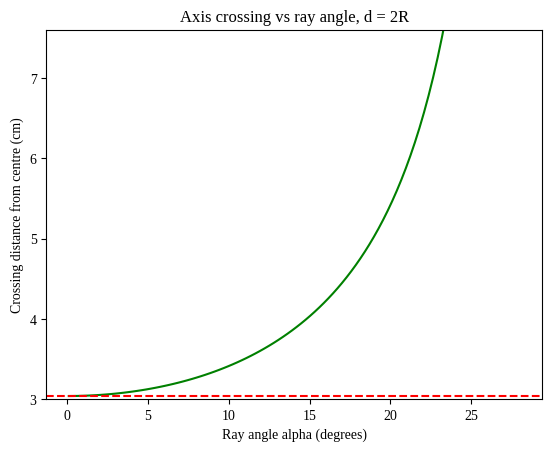

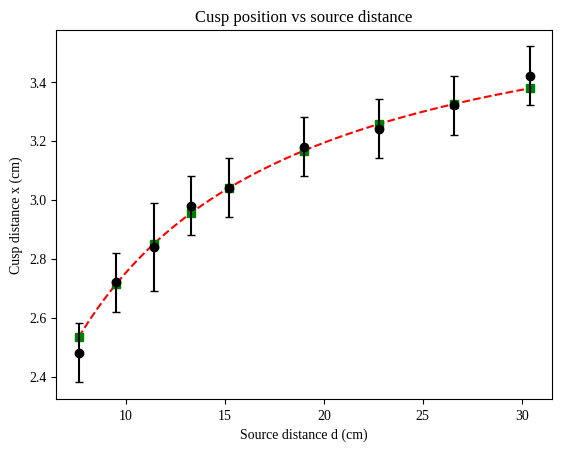

['.config', 'aberration.png', 'cusp_vs_distance.png', 'caustic_2R.png', 'caustics_1R_4R.png', 'sample_data']


In [45]:
d = 15.2
x_pred = R * d / (2 * d + R)

# Figure 1: caustic at d = 2R
plt.plot(ring_x, ring_y, "k")
for alpha in np.radians(np.linspace(-28, 28, 41)):
    source, Q, r = trace_ray(d, alpha)
    end = Q + (-2 * np.dot(Q, r)) * r
    plt.plot([source[0], Q[0]], [source[1], Q[1]], "b", linewidth=0.3)
    plt.plot([Q[0], end[0]], [Q[1], end[1]], "g", linewidth=0.5)
plt.plot(source[0], source[1], "y*", markersize=15)
plt.plot(-x_pred, 0, "rx")
plt.axis("equal")
plt.title("41 rays, LED at d = 2R")
plt.xlabel("x (cm)")
plt.ylabel("y (cm)")
plt.savefig("caustic_2R.png", dpi=150, bbox_inches="tight")
plt.show()

# Figure 2: spherical aberration
alphas_deg = np.linspace(0.1, 28, 100)
crossings = []
for a in alphas_deg:
    crossings.append(axis_crossing(d, np.radians(a)))

plt.plot(alphas_deg, crossings, "g")
plt.axhline(x_pred, color="r", linestyle="--")
plt.ylim(3, 7.6)
plt.title("Axis crossing vs ray angle, d = 2R")
plt.xlabel("Ray angle alpha (degrees)")
plt.ylabel("Crossing distance from centre (cm)")
plt.savefig("aberration.png", dpi=150, bbox_inches="tight")
plt.show()

# Figure 3: simulation vs experiment
d_smooth = np.linspace(7.6, 30.4, 100)
plt.plot(d_smooth, R * d_smooth / (2 * d_smooth + R), "r--")
plt.plot(d_values, x_sim, "gs")
plt.errorbar(d_values, x_measured, yerr=x_error, fmt="ko", capsize=3)
plt.title("Cusp position vs source distance")
plt.xlabel("Source distance d (cm)")
plt.ylabel("Cusp distance x (cm)")
plt.savefig("cusp_vs_distance.png", dpi=150, bbox_inches="tight")
plt.show()

import os
print(os.listdir())